In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset path:", dataset_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset path: /kaggle/input/chest-xray-pneumonia


In [ ]:
import os

print(os.listdir(dataset_path))

['chest_xray']


In [ ]:
data_dir = dataset_path

print(os.listdir(data_dir))

['chest_xray']


In [ ]:
train_dir = os.path.join(data_dir, "train")
val_dir   = os.path.join(data_dir, "val")
test_dir  = os.path.join(data_dir, "test")

print("Train:", train_dir)
print("Validation:", val_dir)
print("Test:", test_dir)

Train: /kaggle/input/chest-xray-pneumonia/train
Validation: /kaggle/input/chest-xray-pneumonia/val
Test: /kaggle/input/chest-xray-pneumonia/test


In [ ]:
import os

# Correctly define the base data directory by including the 'chest_xray' subdirectory
corrected_data_dir = os.path.join(dataset_path, "chest_xray")

# Redefine train_dir, val_dir, and test_dir using the corrected base path
train_dir = os.path.join(corrected_data_dir, "train")
val_dir   = os.path.join(corrected_data_dir, "val")
test_dir  = os.path.join(corrected_data_dir, "test")

print("Train:", os.listdir(train_dir))
print("Validation:", os.listdir(val_dir))
print("Test:", os.listdir(test_dir))

Train: ['PNEUMONIA', 'NORMAL']
Validation: ['PNEUMONIA', 'NORMAL']
Test: ['PNEUMONIA', 'NORMAL']


In [ ]:
import os

# Assuming `corrected_data_dir` is already defined from a previous cell,
# otherwise it would need to be defined here: corrected_data_dir = os.path.join(dataset_path, "chest_xray")

for folder in ["train", "val", "test"]:
    path = os.path.join(corrected_data_dir, folder)
    print(f"\n{folder}:")
    print(os.listdir(path))


train:
['PNEUMONIA', 'NORMAL']

val:
['PNEUMONIA', 'NORMAL']

test:
['PNEUMONIA', 'NORMAL']


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

In [ ]:
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [ ]:
import os
import kagglehub

# Ensure dataset_path is defined
dataset_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

# Correctly define data_dir to include the 'chest_xray' subdirectory
data_dir = os.path.join(dataset_path, "chest_xray")

train_dir = os.path.join(data_dir, "train")
val_dir   = os.path.join(data_dir, "val")
test_dir  = os.path.join(data_dir, "test")

print("Train:", train_dir)
print("Validation:", val_dir)
print("Test:", test_dir)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Train: /kaggle/input/chest-xray-pneumonia/chest_xray/train
Validation: /kaggle/input/chest-xray-pneumonia/chest_xray/val
Test: /kaggle/input/chest-xray-pneumonia/chest_xray/test


In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
from torchvision import datasets

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=val_test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=val_test_transform
)

In [ ]:
print("Classes:", train_dataset.classes)
print("Class indices:", train_dataset.class_to_idx)

Classes: ['NORMAL', 'PNEUMONIA']
Class indices: {'NORMAL': 0, 'PNEUMONIA': 1}


In [ ]:
print("Number of training images:", len(train_dataset))
print("Number of validation images:", len(val_dataset))
print("Number of testing images:", len(test_dataset))

Number of training images: 5216
Number of validation images: 16
Number of testing images: 624


In [ ]:
from torch.utils.data import DataLoader

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


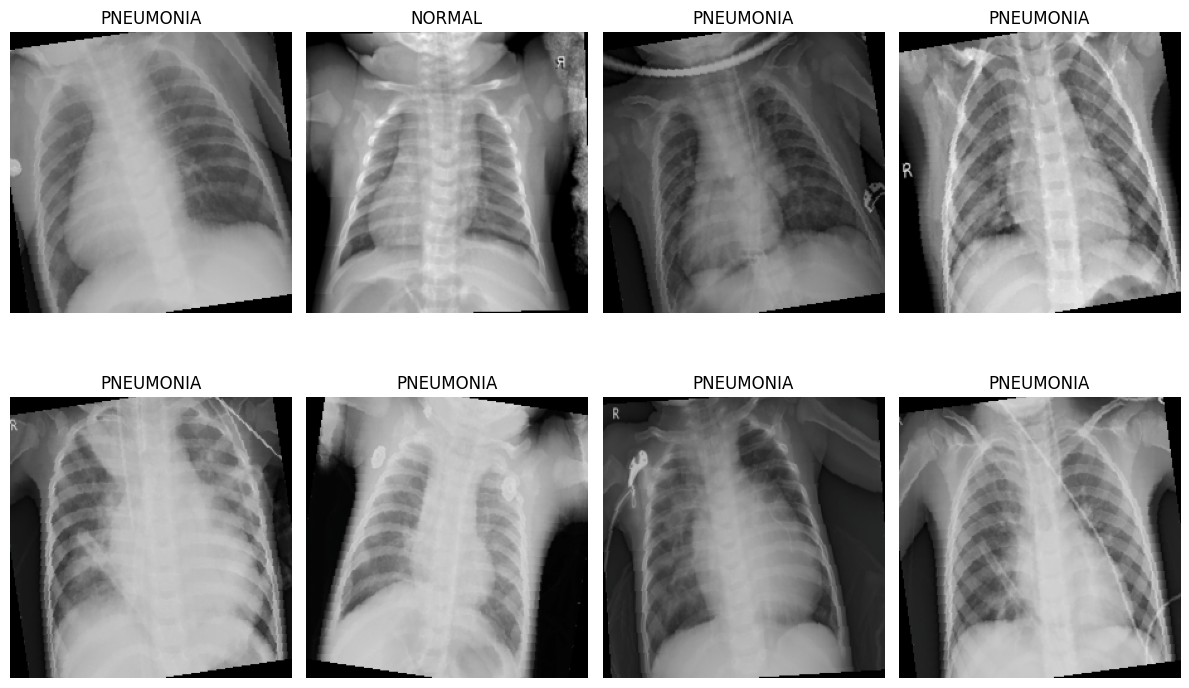

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

images, labels = next(iter(train_loader))

plt.figure(figsize=(12, 8))

for i in range(8):
    plt.subplot(2, 4, i + 1)

    image = images[i].permute(1, 2, 0).numpy()

    # Undo normalization for visualization
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    image = image * std + mean
    image = np.clip(image, 0, 1)

    plt.imshow(image)
    plt.title(train_dataset.classes[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from torchvision import models

weights = models.ResNet18_Weights.DEFAULT

model = models.resnet18(weights=weights)

print(model)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 147MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

In [ ]:
import torch.nn as nn

num_features = model.fc.in_features

model.fc = nn.Linear(num_features, 2)

model = model.to(device)

In [ ]:
print(model.fc)

Linear(in_features=512, out_features=2, bias=True)


In [ ]:
criterion = nn.CrossEntropyLoss()

In [ ]:
import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

In [ ]:
print("Device:", device)
print("Classes:", train_dataset.classes)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))
print("Number of classes:", len(train_dataset.classes))

Device: cuda
Classes: ['NORMAL', 'PNEUMONIA']
Training images: 5216
Validation images: 16
Testing images: 624
Number of classes: 2


In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
num_epochs = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

best_val_accuracy = 0.0

for epoch in range(num_epochs):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.4f}"
    )

    # Save the best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "best_resnet18_pneumonia.pth"
        )

        print("  → Best model saved!")

Epoch [1/10] Train Loss: 0.1044 Train Acc: 0.9653 Val Loss: 0.1389 Val Acc: 1.0000
  → Best model saved!
Epoch [2/10] Train Loss: 0.0590 Train Acc: 0.9787 Val Loss: 0.2523 Val Acc: 0.9375
Epoch [3/10] Train Loss: 0.0451 Train Acc: 0.9835 Val Loss: 1.1155 Val Acc: 0.6250
Epoch [4/10] Train Loss: 0.0305 Train Acc: 0.9896 Val Loss: 0.1317 Val Acc: 0.9375
Epoch [5/10] Train Loss: 0.0261 Train Acc: 0.9895 Val Loss: 0.5719 Val Acc: 0.7500
Epoch [6/10] Train Loss: 0.0302 Train Acc: 0.9885 Val Loss: 0.1039 Val Acc: 0.9375
Epoch [7/10] Train Loss: 0.0195 Train Acc: 0.9937 Val Loss: 0.1536 Val Acc: 0.9375
Epoch [8/10] Train Loss: 0.0135 Train Acc: 0.9950 Val Loss: 0.3800 Val Acc: 0.8750
Epoch [9/10] Train Loss: 0.0226 Train Acc: 0.9912 Val Loss: 0.8898 Val Acc: 0.6875
Epoch [10/10] Train Loss: 0.0169 Train Acc: 0.9944 Val Loss: 0.4784 Val Acc: 0.7500


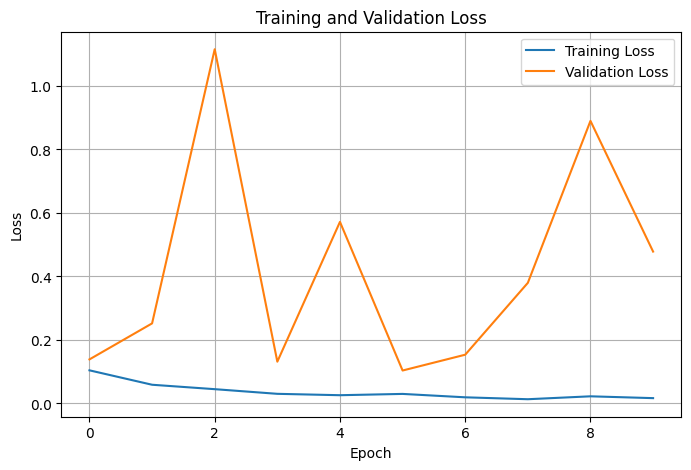

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

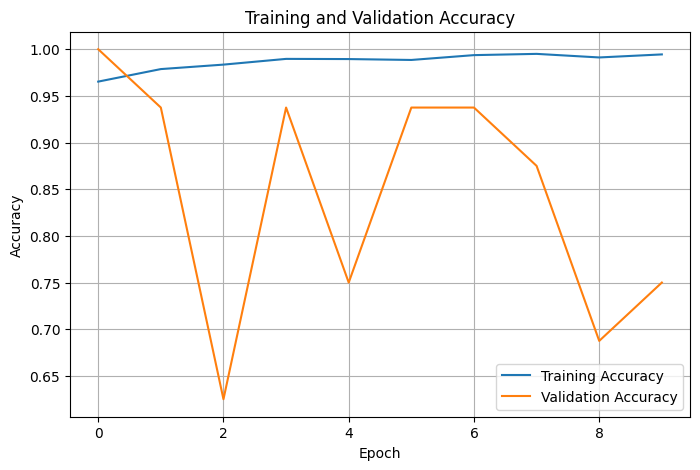

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

In [ ]:
# Load the best model
model.load_state_dict(
    torch.load(
        "best_resnet18_pneumonia.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Best model loaded successfully!")

Best model loaded successfully!


In [ ]:
all_labels = []
all_predictions = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

print("Total test images:", len(all_labels))
print("Total predictions:", len(all_predictions))

Total test images: 624
Total predictions: 624


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

In [ ]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

print(cm)

[[152  82]
 [  6 384]]


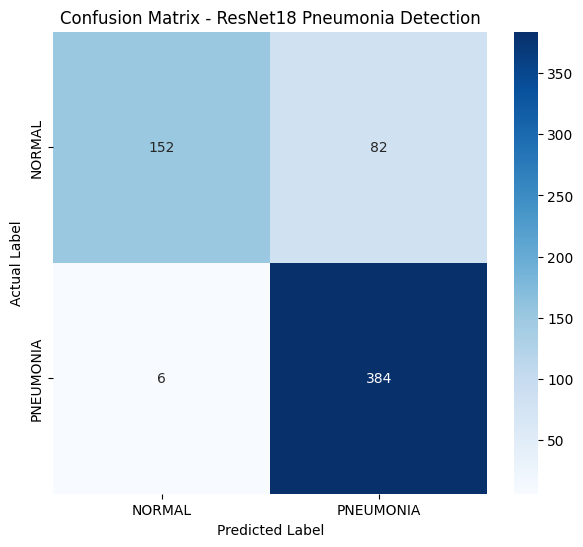

In [ ]:
plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - ResNet18 Pneumonia Detection")

plt.show()

In [ ]:
print(train_dataset.class_to_idx)

{'NORMAL': 0, 'PNEUMONIA': 1}


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    pos_label=1
)

recall = recall_score(
    all_labels,
    all_predictions,
    pos_label=1
)

f1 = f1_score(
    all_labels,
    all_predictions,
    pos_label=1
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.8589743589743589
Precision: 0.8240343347639485
Recall   : 0.9846153846153847
F1 Score : 0.897196261682243


In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=train_dataset.classes
    )
)

              precision    recall  f1-score   support

      NORMAL       0.96      0.65      0.78       234
   PNEUMONIA       0.82      0.98      0.90       390

    accuracy                           0.86       624
   macro avg       0.89      0.82      0.84       624
weighted avg       0.88      0.86      0.85       624



In [ ]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 3.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files

from torchvision import transforms

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
model.load_state_dict(
    torch.load(
        "best_resnet18_pneumonia.pth",
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("ResNet18 model loaded.")

ResNet18 model loaded.


In [ ]:
target_layers = [model.layer4[-1]]

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
uploaded = files.upload()

Saving person3_virus_17.jpeg to person3_virus_17.jpeg


In [ ]:
# Get uploaded filename
image_path = list(uploaded.keys())[0]

# Open image
original_image = Image.open(image_path).convert("RGB")

# Resize for model
input_image = original_image.resize((224, 224))

# Convert image to numpy
rgb_image = np.array(input_image).astype(np.float32) / 255.0

# Preprocess for ResNet18
input_tensor = transform(input_image).unsqueeze(0).to(device)

# Prediction
model.eval()

with torch.no_grad():
    outputs = model(input_tensor)
    probabilities = torch.softmax(outputs, dim=1)

predicted_class = torch.argmax(probabilities, dim=1).item()

class_names = train_dataset.classes
predicted_label = class_names[predicted_class]

print("Prediction:", predicted_label)

for i, class_name in enumerate(class_names):
    print(
        f"{class_name}: "
        f"{probabilities[0][i].item() * 100:.2f}%"
    )

Prediction: NORMAL
NORMAL: 54.29%
PNEUMONIA: 45.71%


In [ ]:
# Create Grad-CAM object
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

# Tell Grad-CAM which class to explain
targets = [
    ClassifierOutputTarget(predicted_class)
]

# Generate CAM
grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

# Create overlay
visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

In [ ]:
# Create Grad-CAM object
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

# Tell Grad-CAM which class to explain
targets = [
    ClassifierOutputTarget(predicted_class)
]

# Generate CAM
grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

# Create overlay
visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

Grad-CAM shape: (224, 224)
Visualization shape: (224, 224, 3)


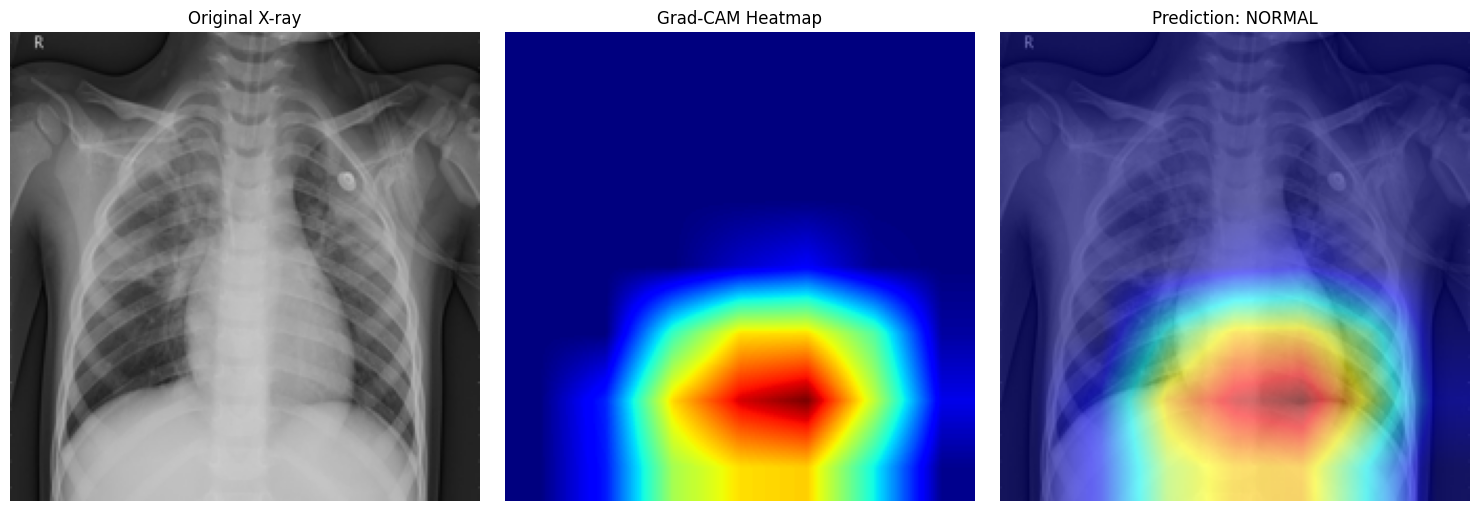

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# ------------------------------------------------
# 1. Check model
# ------------------------------------------------
model.eval()

# ------------------------------------------------
# 2. Select target layer of ResNet18
# ------------------------------------------------
target_layers = [model.layer4[-1]]

# ------------------------------------------------
# 3. Create Grad-CAM
# ------------------------------------------------
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

# ------------------------------------------------
# 4. Generate Grad-CAM
# ------------------------------------------------
targets = [
    ClassifierOutputTarget(predicted_class)
]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

print("Grad-CAM shape:", grayscale_cam.shape)

# ------------------------------------------------
# 5. Create overlay
# ------------------------------------------------
visualization = show_cam_on_image(
    rgb_image,
    grayscale_cam,
    use_rgb=True
)

print("Visualization shape:", visualization.shape)

# ------------------------------------------------
# 6. Display
# ------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(rgb_image)
axes[0].set_title("Original X-ray")
axes[0].axis("off")

axes[1].imshow(grayscale_cam, cmap="jet")
axes[1].set_title("Grad-CAM Heatmap")
axes[1].axis("off")

axes[2].imshow(visualization)
axes[2].set_title(f"Prediction: {predicted_label}")
axes[2].axis("off")

plt.tight_layout()
plt.show()